# Industrial Surface Defect Classification using Transfer Learning

## Objective

The aim of this assignment is to automatically classify surface defects in steel materials using real-world industrial image data and a transfer learning approach.

Surface defects such as cracks, scratches, inclusions, and pits commonly occur during manufacturing processes and can significantly affect product quality. Manual inspection of these defects is time-consuming, inconsistent, and difficult to scale.

In this assignment, we use a dataset containing steel surface images belonging to six different defect categories:
- Crazing  
- Inclusion  
- Patches  
- Pitted Surface  
- Rolled-in Scale  
- Scratches  

All defect types originate from the same manufacturing domain, and learning from all categories together allows the model to capture shared texture and structural patterns present across industrial surfaces.

The problem statement for this assignment is:

> **Given a steel surface image, predict the type of surface defect present in the image using a pretrained convolutional neural network.**

To solve this problem efficiently, we apply **transfer learning** by reusing a pretrained `MobileNetV2` model as a feature extractor and training only a lightweight classification head. This demonstrates how deep learning models can be adapted to real industrial use cases using limited data and computational resources.

## Business Value

In manufacturing industries such as steel, automotive, and heavy engineering, surface defects can directly impact product quality, safety, customer satisfaction, production cost, and rework rates.

Traditional inspection methods rely heavily on human inspectors, which introduces inconsistency in defect detection. Manual inspection also comes with high operational costs and scalability limitations.

By applying transfer learning, organisations can:
- Reuse pretrained visual intelligence instead of training models from scratch  
- Reduce development and training time  
- Achieve reliable defect detection even with smaller datasets  
- Deploy lightweight models suitable for real-time or edge-based inspection systems

## Dataset Description

This assignment uses the **NEU Surface Defect Dataset**, a real-world industrial dataset commonly used in manufacturing research and automated inspection systems.

### Dataset Characteristics:
- Images represent steel surface textures captured under industrial conditions  
- Each image belongs to one of six defect categories:
  - Crazing  
  - Inclusion  
  - Patches  
  - Pitted Surface  
  - Rolled-in Scale  
  - Scratches  
- Images are originally grayscale
- The dataset is reasonably balanced across classes  


#### Why this dataset?

- It represents a real industrial computer vision problem
- Defect patterns are texture-based, making it ideal for demonstrating transfer learning  
- The dataset size is moderate, encouraging the use of **partial transfer learning** rather than full model retraining  

## Flow Diagram

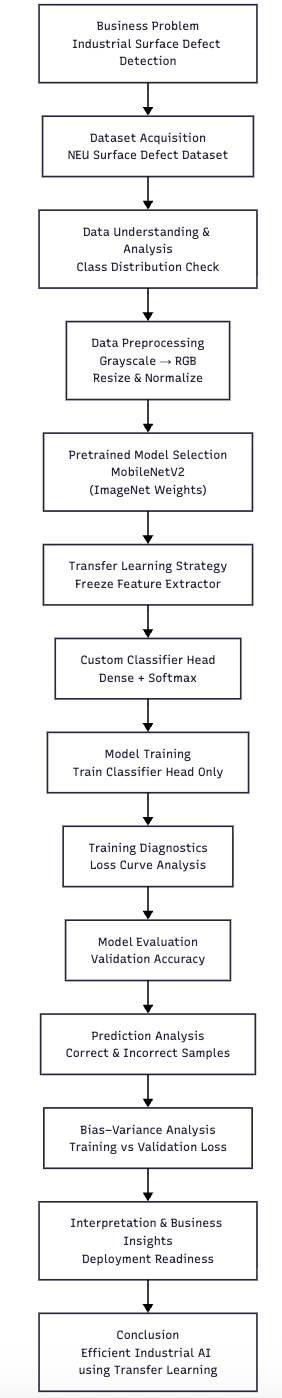

**Note:** You are free to choose any pre-trained model from the available ones. However, the architecture we suggest for this assignment is `MobileNetV2` with "ImageNet" weights.

The choice of libraries, frameworks, and backbones for this assignment are up to you. Before starting this assignment, please ensure that your environment meets the following requirements.


**Software Requirements**

- *Python version*: > Python3.11  
- *Execution environment*: Jupyter Notebook / JupyterLab / VS Code Notebook  
- *Operating system*: macOS, Linux, or Windows  


**Hardware Requirements**
- A GPU-powered training would be optimal, and would require installation of proper libraries and CUDA
- However, CPU-only execution might also be sufficient, and would work without CUDA

### Import Necessary libraries

In [3]:
# Import Required Libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#tensor flow or keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

#Pre trained mobileNetV2
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

#Image Dataset loading
from tensorflow.keras.utils import image_dataset_from_directory

#Model Evaluation
from sklearn.metrics import (
classification_report,
confusion_matrix,
accuracy_score
)

## 1. Data Loading and Preparation

<font color=red>[10 marks]</font>

In any machine learning workflow, understanding and preparing the data correctly is a critical first step. Before building a deep learning model, it is important
to examine how the dataset is structured, how labels are assigned, and how images are preprocessed for training.

This section includes the following steps:
- Understanding the dataset organisation
- Verifying class labels and distributions
- Applying appropriate image transformations for transfer learning
- Development of train loader and validation loader

### 1.1 Dataset Understanding and Structure

<font color=red>[4 marks]</font>

The NEU Surface Defect Dataset consists of real-world grayscale images collected from steel manufacturing processes. Each image belongs to one of six surface defect categories.

The dataset is already split into **training** and **validation** sets, and images are organised into class-specific folders. This structure allows us to use PyTorch’s `ImageFolder` utility, which automatically assigns labels based on directory names.

The same directory-based structure is also compatible with TensorFlow, allowing the dataset to be loaded directly using `tf.keras.utils.image_dataset_from_directory`, which infers class labels from folder names in a similar manner.



Before proceeding, we load the dataset and verify:
- Number of images in training and validation sets
- Mapping between class names and numeric labels

#### **1.1.1** Load Images and Labels  <font color=red>[3 marks]</font>

Load the training and validation datasets and check the number of images and the number of categories present

In [4]:
# Load training and validation images + labels

# Load data
!ls /content #Verify the uploaded File
!unzip -q "/content/NEU-DET.zip" -d "/content/NEU-DET" #Unzip the Zipped file
!find "/content/NEU-DET" -maxdepth 3 -type d #Folder Hierarchy

train_dir = "/content/NEU-DET/NEU-DET/train"
val_dir = "/content/NEU-DET/NEU-DET/validation"

print("Training classes:")
print(os.listdir(train_dir))

print("\nValidation classes:")
print(os.listdir(val_dir))


# Dataset statistics

# Path containing the actual class folders
train_images_dir = os.path.join(train_dir, "images")
val_images_dir = os.path.join(val_dir, "images")

# Supported image extensions
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

# Get the class/category names
class_names = sorted([
folder for folder in os.listdir(train_images_dir)
if os.path.isdir(os.path.join(train_images_dir, folder))
])

# Count total number of training images and validation imaegs
num_train_images = sum(
1
for root, dirs, files in os.walk(train_images_dir)
for file in files
if file.lower().endswith(image_extensions)
)

num_val_images = sum(
1
for root, dirs, files in os.walk(val_images_dir)
for file in files
if file.lower().endswith(image_extensions)
)

# Number of categories
num_categories = len(class_names)

# Display statistics
print("\nDataset Statistics")
print("----------------------------")
print("Number of training images :", num_train_images)
print("Number of validation images :", num_val_images)
print("Number of categories :", num_categories)

print("\nCategories:")
for index, class_name in enumerate(class_names):
  print(f"{index} -> {class_name}")

NEU-DET  NEU-DET.zip  sample_data
replace /content/NEU-DET/NEU-DET/train/annotations/crazing_61.xml? [y]es, [n]o, [A]ll, [N]one, [r]ename: /content/NEU-DET
/content/NEU-DET/NEU-DET
/content/NEU-DET/NEU-DET/validation
/content/NEU-DET/NEU-DET/validation/annotations
/content/NEU-DET/NEU-DET/validation/images
/content/NEU-DET/NEU-DET/train
/content/NEU-DET/NEU-DET/train/annotations
/content/NEU-DET/NEU-DET/train/images
Training classes:
['annotations', 'images']

Validation classes:
['annotations', 'images']

Dataset Statistics
----------------------------
Number of training images : 1440
Number of validation images : 360
Number of categories : 6

Categories:
0 -> crazing
1 -> inclusion
2 -> patches
3 -> pitted_surface
4 -> rolled-in_scale
5 -> scratches


Here, the image loader automatically assigns numeric labels based on folder names. For example, all images inside the "crazing" folder receive the same label.

This approach reduces manual labeling effort and ensures consistency between directory structure and class definitions.

#### **1.1.2** Check and Visualise Class Distribution <font color=red>[1 mark]</font>

In [5]:
# Dataset Class Distribution

#Class Distribution

train_class_counts = []
val_class_counts = []

for class_name in class_names:

    # Path for each class in training dataset
    train_class_path = os.path.join(train_images_dir, class_name)

    # Path for each class in validation dataset
    val_class_path = os.path.join(val_images_dir, class_name)

    # Count training images for the class
    train_count = sum(
        1
        for file in os.listdir(train_class_path)
        if file.lower().endswith(image_extensions)
    )

    # Count validation images for the class
    val_count = sum(
        1
        for file in os.listdir(val_class_path)
        if file.lower().endswith(image_extensions)
    )

    train_class_counts.append(train_count)
    val_class_counts.append(val_count)



# Create a DataFrame to display class distribution
class_distribution = pd.DataFrame({
    "Defect Class": class_names,
    "Training Images": train_class_counts,
    "Validation Images": val_class_counts
})

print("\nClass Distribution")
print("---------------------------------------------")
print(class_distribution.to_string(index=False))


Class Distribution
---------------------------------------------
   Defect Class  Training Images  Validation Images
        crazing              240                 60
      inclusion              240                 60
        patches              240                 60
 pitted_surface              240                 60
rolled-in_scale              240                 60
      scratches              240                 60


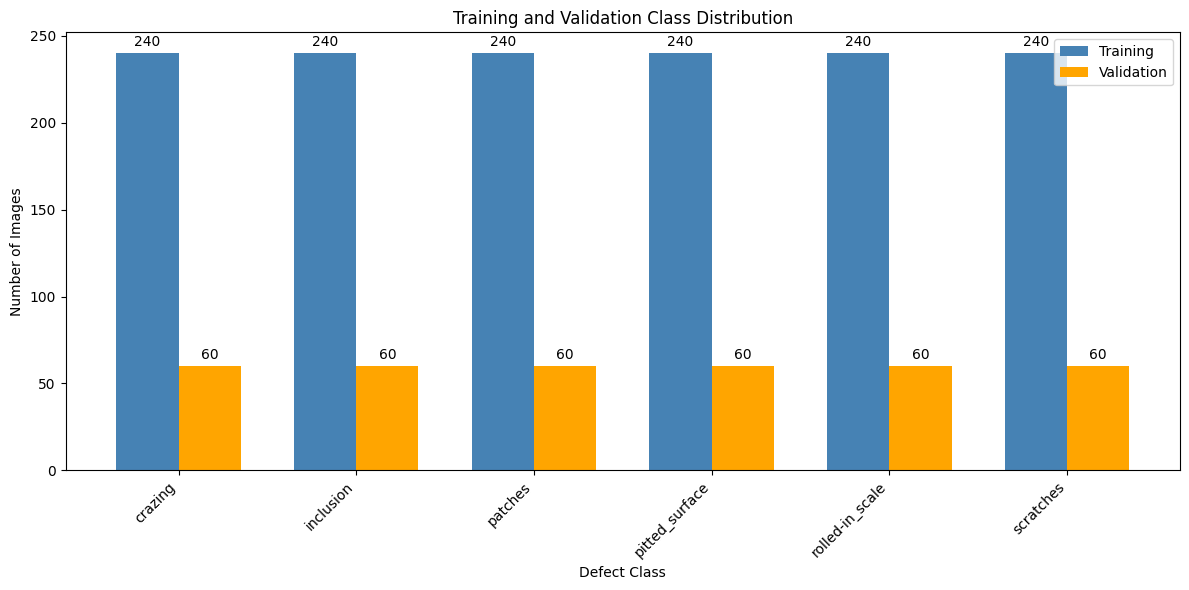

In [6]:
# Visualise class distribution

import numpy as np
import matplotlib.pyplot as plt

# Create x-axis positions for each class
x = np.arange(len(class_names))

# Width of each bar
width = 0.35

# Create figure
fig, ax = plt.subplots(figsize=(12, 6))

# Training bars
train_bars = ax.bar(
    x - width/2,
    train_class_counts,
    width,
    label="Training",
    color="steelblue"
)

# Validation bars
val_bars = ax.bar(
    x + width/2,
    val_class_counts,
    width,
    label="Validation",
    color="orange"
)

# Add count values above bars
ax.bar_label(train_bars, padding=3)
ax.bar_label(val_bars, padding=3)

# Add labels and title
ax.set_title("Training and Validation Class Distribution")
ax.set_xlabel("Defect Class")
ax.set_ylabel("Number of Images")

# Set class names on x-axis
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=45, ha="right")

# Add legend
ax.legend()

# Adjust layout
plt.tight_layout()

# Display graph
plt.show()

### 1.2 Data Preprocessing and Transformations

<font color=red>[6 marks]</font>

Deep learning models pretrained on ImageNet expect images to be in a specific format. Although the NEU dataset images are grayscale, ImageNet-pretrained models require 3-channel RGB images with standardised dimensions and normalisation.

#### **1.2.1** Apply Image Transformations <font color=red>[4 marks]</font>

To ensure compatibility, we apply the following transformations:
- Convert grayscale images to RGB
- Resize images to a fixed resolution
- Normalize using ImageNet mean and standard deviation

These transformations are provided in [`transforms`](https://docs.pytorch.org/vision/0.24/transforms.html) from `torchvision`, while in TensorFlow the same preprocessing steps are applied using [`tf.image`](https://www.tensorflow.org/api_docs/python/tf/image) operations and `tf.keras.layers` within the input pipeline.

In PyTorch, normalization can be performed using `Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)`.

In TensorFlow, the same effect is achieved by explicitly standardising the images with the ImageNet statistics, i.e. subtracting `IMAGENET_MEAN` and dividing by `IMAGENET_STD` using `tf.image` operations or a custom `tf.keras.layers.Layer` within the preprocessing pipeline.

In [7]:
# Image Transformations

IMG_HEIGHT = 224
IMG_WIDTH = 224

# ImageNet normalization statistics
IMAGENET_MEAN = tf.constant(
[0.485, 0.456, 0.406],
dtype=tf.float32
)

IMAGENET_STD = tf.constant(
[0.229, 0.224, 0.225],
dtype=tf.float32
)

#Applying Image Transformation
def transform_image(image, label):

    # Convert image to float32 and scale pixel values
    # from [0, 255] to [0, 1]
    image = tf.image.convert_image_dtype(image, tf.float32)

    # Convert grayscale image to RGB if required
    if image.shape[-1] == 1:
        image = tf.image.grayscale_to_rgb(image)

    # Resize image to 224 x 224
    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH]
    )

    # Normalize using ImageNet mean and standard deviation
    image = (image - IMAGENET_MEAN) / IMAGENET_STD

    return image, label

At this stage, the dataset is fully prepared for training a transfer learning model. Images are correctly formatted, normalized, and labeled, ensuring a smooth transition into model design and training.

#### **1.2.2** Create DataLoaders for both the training and validation datasets <font color=red>[2 marks]</font>


Deep learning models are trained on data in **batches** rather than loading the entire dataset into memory at once.

PyTorch provides the [`DataLoader`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) utility to batch the data, shuffle training samples and load data efficiently during training. For Tensorflow, you can use similar functionality provided by [`tf.data.Dataset` API](https://www.tensorflow.org/api_docs/python/tf/data/Dataset), which supports efficient batching, shuffling, prefetching, and parallel data loading within the input pipeline.

In [8]:
# DataLoader Creation

#Create DataLoader
BATCH_SIZE = 32
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

#Create Training Dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
train_images_dir,
labels="inferred",
label_mode="int",
color_mode="grayscale",
image_size=(IMG_HEIGHT, IMG_WIDTH),
batch_size=BATCH_SIZE,
shuffle=True,
seed=SEED
)

#Create Validation Dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
val_images_dir,
labels="inferred",
label_mode="int",
color_mode="grayscale",
image_size=(IMG_HEIGHT, IMG_WIDTH),
batch_size=BATCH_SIZE,
shuffle=False
)

#Apply Transformation
train_ds = train_ds.map(
transform_image,
num_parallel_calls=AUTOTUNE
)

val_ds = val_ds.map(
transform_image,
num_parallel_calls=AUTOTUNE
)

#Prefetch Data
train_loader = train_ds.prefetch(buffer_size=AUTOTUNE)
val_loader = val_ds.prefetch(buffer_size=AUTOTUNE)

print("\nDataLoaders created successfully")
print("Training DataLoader :", train_loader)
print("Validation DataLoader :", val_loader)


Found 1440 files belonging to 6 classes.
Found 360 files belonging to 6 classes.

DataLoaders created successfully
Training DataLoader : <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
Validation DataLoader : <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


Also decide on where to use shuffling - training or validation


Answer: Model updates its weights after processing each batch. Without shuffling, samples can arrive in a predictable order.
Hence we shuffle training samples to avoid model learning teh patterns associated with ordering .

Validation data is not used to update model weights. Hence Validation data need not be shuffled

## 2. Transferring Knowledge and Model Training

<font color=red>[25 marks]</font>

Training deep learning models from scratch requires large amounts of labeled data and computational resources. In many real-world scenarios, this is not feasible. Transfer learning addresses this challenge by reusing knowledge learned from a large source dataset (such as ImageNet) and adapting it to a new, related task.

### 2.1 Pretrained Model Selection

<font color=red>[15 marks]</font>

For this assignment, we will prefer **MobileNetV2**, a lightweight convolutional neural network pretrained on the ImageNet dataset. Though any pre-trained network will suit the task.

MobileNetV2 is computationally efficient and lightweight. It performs well on texture-based image classification tasks.

In this section:
- Select a suitable pretrained convolutional neural network
- Apply a partial transfer learning strategy
- Design a task-specific classifier for surface defect detection

#### **2.1.1** Load the Pre-Trained Model <font color=red>[5 marks]</font>

Load the pre-trained model of your choice. If you wish to use a different architecture from MobileNet, also explain the reason for your choice.

In [9]:
# Load Pretrained Network

base_model = MobileNetV2(
weights="imagenet",
include_top=False,
input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)

# Display model summary
base_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 2,223,872 (8.48 MB)

 Non-trainable params: 34,112 (133.25 KB)

The MobileNetV2 architecture consists of two main components:
- A **feature extractor** that learns visual representations
- A **classifier head** originally designed for ImageNet’s 1000 classes

#### **2.1.2** Freezing Strategy and Classifier Design <font color=red>[8 marks]</font>

Build the transfer learning model by loading and freezing the feature extractor layers.


Instead of retraining the entire network, we apply partial transfer learning. In this approach the pretrained feature extractor is frozen and only the classifier head is retrained for the new task. This strategy reduces the risk of overfitting and speeds up training.

In [10]:
# Build Transfer Learning Model

base_model.trainable = False

num_classes = len(class_names) # Should be 6

model = tf.keras.Sequential([
# Input

tf.keras.layers.Input(
shape=(IMG_HEIGHT, IMG_WIDTH, 3)
),

# Pretrained MobileNetV2 feature extractor
base_model,

# Convert feature maps into a feature vector
tf.keras.layers.GlobalAveragePooling2D(),

# Dropout for regularization
tf.keras.layers.Dropout(0.2),

# Classification layer for 6 defect classes
tf.keras.layers.Dense(
num_classes,
activation="softmax"
)
])

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

#### **2.1.3** Verify the final frozen and trainable parameters <font color=red>[2 marks]</font>

In [11]:
# Verify Freezing Strategy

# Count trainable parameters
trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.trainable_weights
])

# Count frozen / non-trainable parameters
non_trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.non_trainable_weights
])

# Total parameters
total_params = model.count_params()

print("Parameter Summary")
print("----------------------------------")
print(f"Total parameters         : {total_params:,}")
print(f"Trainable parameters     : {int(trainable_params):,}")
print(f"Non-trainable parameters : {int(non_trainable_params):,}")

Parameter Summary
----------------------------------
Total parameters         : 2,265,670
Trainable parameters     : 7,686
Non-trainable parameters : 2,257,984


### 2.2 Model Training

<font color=red>[10 marks]</font>

After designing the transfer learning model, the next step is to train it on the prepared dataset.

We only train the classifier head, while the pretrained feature extractor remains frozen. This allows the model to adapt quickly to the surface defect classification task.

In this section, we:
- Configure the training setup
- Train the model for a small number of epochs
- Track training loss to verify learning progress

#### **2.2.1** Training Configuration <font color=red>[3 marks]</font>

Before starting the training loop, we define:
- The computation device: CPU or GPU
- The loss function: Use a suitable loss function (one of the cross-entropy losses would work fine here)
- The optimizer: preferably [Adam](https://arxiv.org/abs/1412.6980) from [Tensorflow](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam) or [Pytorch](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html)

These components control how the model learns from data and how its parameters are updated during training.

In [12]:
# Training Configuration

#1. Check computation device
gpus = tf.config.list_physical_devices("GPU")

if gpus:
  print("Training Device : GPU")
else:
  print("Training Device : CPU")

# 2. Define loss function
# Suitable because class labels are integers: 0, 1, 2, 3, 4, 5
loss_function = tf.keras.losses.SparseCategoricalCrossentropy()

# 3. Define optimizer
optimizer = tf.keras.optimizers.Adam(
learning_rate=0.001
)

# 4. Compile the model
model.compile(
optimizer=optimizer,
loss=loss_function,
metrics=["accuracy"]
)

# 5. Number of training epochs
EPOCHS = 10

print("\nTraining Configuration")
print("--------------------------------")
print("Loss Function : SparseCategoricalCrossentropy")
print("Optimizer : Adam")
print("Learning Rate : 0.001")
print("Epochs :", EPOCHS)

Training Device : CPU

Training Configuration
--------------------------------
Loss Function : SparseCategoricalCrossentropy
Optimizer : Adam
Learning Rate : 0.001
Epochs : 10


#### **2.2.2** Model Training Loop <font color=red>[5 marks]</font>

Perform the training and track the training loss across epochs to verify whether the model is learning effectively.

The training loop iterates over the dataset multiple times (epochs). For each batch of images, the model:
- Performs a forward pass
- Computes the loss
- Updates the trainable parameters using backpropagation

In [13]:
# Model Training

history = model.fit(
train_loader,
validation_data=val_loader,
epochs=EPOCHS,
verbose=1
)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 93s 2s/step - accuracy: 0.4458 - loss: 1.2552 - val_accuracy: 0.6167 - val_loss: 0.9183
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.6847 - loss: 0.8005 - val_accuracy: 0.6889 - val_loss: 0.7796
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.7236 - loss: 0.6786 - val_accuracy: 0.7139 - val_loss: 0.7007
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.7681 - loss: 0.5978 - val_accuracy: 0.7111 - val_loss: 0.6726
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 75s 2s/step - accuracy: 0.7819 - loss: 0.5469 - val_accuracy: 0.7389 - val_loss: 0.6095
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.8035 - loss: 0.5110 - val_accuracy: 0.7556 - val_loss: 0.6084
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 76s 2s/step - accuracy: 0.8278 - loss: 0.4630 - val_accuracy: 0.7722 - val_loss: 0.5610
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.8417 - loss: 0.4380 - val_accuracy: 0.7861 - val_loss:

#### **2.2.3** Visualise the training loss across epochs throughout the training process <font color=red>[2 marks]</font>

In [14]:
# Training Loss Visualisation

training_loss = history.history["loss"]
validation_loss = history.history["val_loss"]

for epoch in range(len(training_loss)):
  print(
  f"Epoch {epoch + 1}: "
  f"Training Loss = {training_loss[epoch]:.4f}, "
  f"Validation Loss = {validation_loss[epoch]:.4f}"
)

Epoch 1: Training Loss = 1.2552, Validation Loss = 0.9183
Epoch 2: Training Loss = 0.8005, Validation Loss = 0.7796
Epoch 3: Training Loss = 0.6786, Validation Loss = 0.7007
Epoch 4: Training Loss = 0.5978, Validation Loss = 0.6726
Epoch 5: Training Loss = 0.5469, Validation Loss = 0.6095
Epoch 6: Training Loss = 0.5110, Validation Loss = 0.6084
Epoch 7: Training Loss = 0.4630, Validation Loss = 0.5610
Epoch 8: Training Loss = 0.4380, Validation Loss = 0.5500
Epoch 9: Training Loss = 0.4355, Validation Loss = 0.5520
Epoch 10: Training Loss = 0.4210, Validation Loss = 0.5307


## 3. Evaluation and Final Predictions

<font color=red>[10 marks]</font>

After training the model, it is essential to evaluate how well it performs on unseen data. Evaluation helps us understand whether the model has learned generalisable patterns or has simply memorised the training data.

In this section, we:
- Measure model performance using validation accuracy
- Analyse predictions at the individual data-point level
- Examine model behavior using diagnostic plots

### 3.1 Evaluation Metrics and Bias-Variance Tradeoff

<font color=red>[6 marks]</font>

#### **3.1.1** Calculate Appropriate Evaluation Metrics to Assess Model Performance <font color=red>[3 marks]</font>

For this multi-class classification problem, we use **accuracy** as the primary evaluation metric.

Accuracy measures the proportion of validation samples that are correctly classified by the model. Since the dataset is reasonably balanced across classes, accuracy provides a reliable indication of overall performance.

In [15]:
# Model Evaluation

# Evaluate the trained model on validation data
val_loss, val_accuracy = model.evaluate(
val_loader,
verbose=1
)

# Display evaluation results
print("\nModel Evaluation Results")
print("--------------------------------")
print(f"Validation Loss : {val_loss:.4f}")
print(f"Validation Accuracy : {val_accuracy:.4f}")
print(f"Validation Accuracy : {val_accuracy * 100:.2f}%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.7861 - loss: 0.5307

Model Evaluation Results
--------------------------------
Validation Loss : 0.5307
Validation Accuracy : 0.7861
Validation Accuracy : 78.61%


#### **3.1.2** Dataset Diagnostics <font color=red>[3 marks]</font>

Beyond accuracy, diagnostic analysis helps assess whether the model is underfitting, overfitting, or generalising well

Analyse this using training and validation loss trends, along with dataset class distribution.

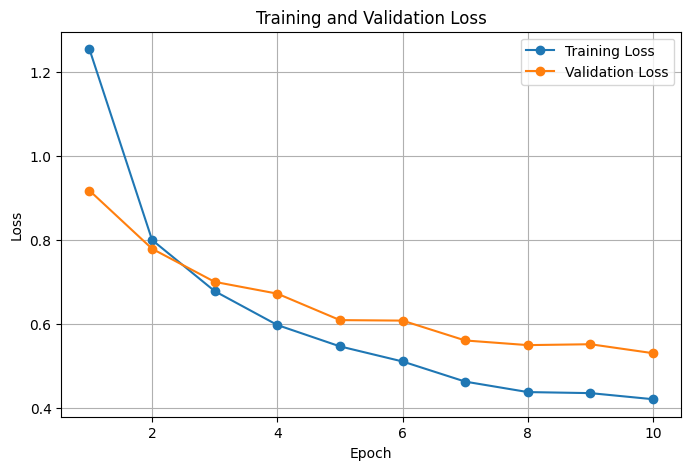

In [16]:
# Training and Validation Loss Analysis

# Extract loss values
training_loss = history.history["loss"]
validation_loss = history.history["val_loss"]

# Epoch numbers
epochs_range = range(1, len(training_loss) + 1)

# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(
epochs_range,
training_loss,
marker="o",
label="Training Loss"
)

plt.plot(
epochs_range,
validation_loss,
marker="o",
label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()


In [20]:
print("Training and Validation Loss")
print("------------------------------------------------")

for epoch in range(len(training_loss)):
  print(
  f"Epoch {epoch + 1}: "
  f"Training Loss = {training_loss}, "
  f"Validation Loss = {validation_loss}"
  )

Training and Validation Loss
------------------------------------------------
Epoch 1: Training Loss = [1.2551591396331787, 0.8004609942436218, 0.6785598993301392, 0.5978490114212036, 0.5469497442245483, 0.5109647512435913, 0.46295610070228577, 0.438037246465683, 0.43553298711776733, 0.42101016640663147], Validation Loss = [0.9183052778244019, 0.7795752882957458, 0.7006773352622986, 0.672603189945221, 0.6095437407493591, 0.6083576083183289, 0.5610406398773193, 0.5499534010887146, 0.5520496964454651, 0.5306714177131653]
Epoch 2: Training Loss = [1.2551591396331787, 0.8004609942436218, 0.6785598993301392, 0.5978490114212036, 0.5469497442245483, 0.5109647512435913, 0.46295610070228577, 0.438037246465683, 0.43553298711776733, 0.42101016640663147], Validation Loss = [0.9183052778244019, 0.7795752882957458, 0.7006773352622986, 0.672603189945221, 0.6095437407493591, 0.6083576083183289, 0.5610406398773193, 0.5499534010887146, 0.5520496964454651, 0.5306714177131653]
Epoch 3: Training Loss = [1.

In [21]:
final_gap = validation_loss[-1] - training_loss[-1]

print("\nFinal Loss Comparison")
print("--------------------------------")
print(f"Final Training Loss : {training_loss[-1]:.4f}")
print(f"Final Validation Loss : {validation_loss[-1]:.4f}")
print(f"Loss Gap : {final_gap:.4f}")


Final Loss Comparison
--------------------------------
Final Training Loss : 0.4210
Final Validation Loss : 0.5307
Loss Gap : 0.1097


### 3.2 Prediction Analysis

<font color=red>[4 marks]</font>

Overall accuracy provides a summary metric, but it does not reveal how individual predictions contribute to that score.

To better understand model behavior, we examine predictions at the individual image level, highlighting both correct and incorrect classifications.

#### **3.2.1** Visualise the prediction on a few sample images from validation set <font color=red>[4 marks]</font>

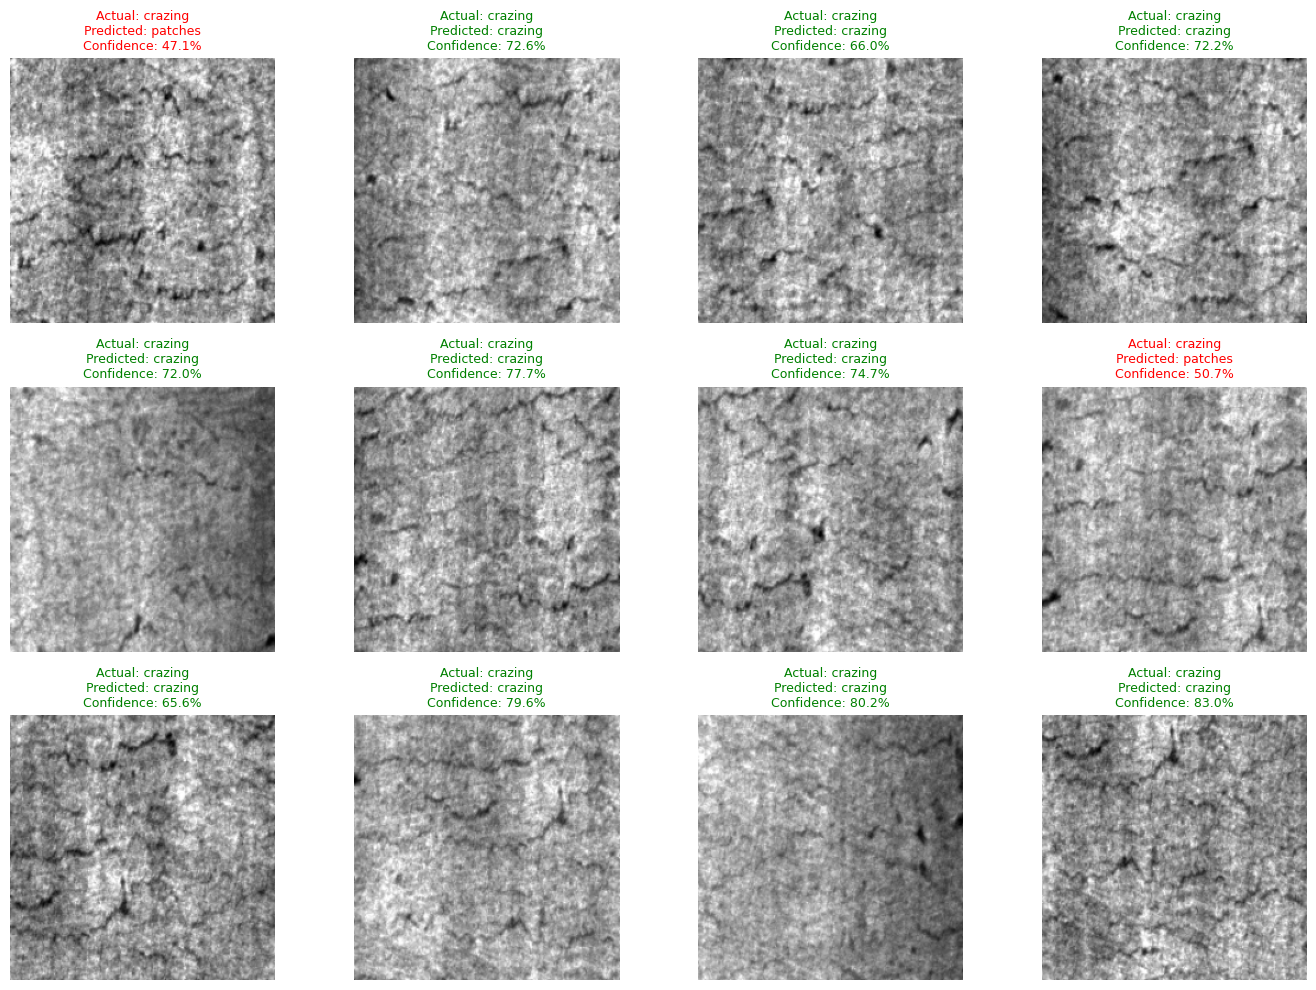

In [24]:
# Visualisation of Validation Predictions


# Get one batch from validation data
for images, labels in val_loader.take(1):

    # Model predictions
    predictions = model.predict(images, verbose=0)

    # Predicted class indices
    predicted_labels = np.argmax(predictions, axis=1)

    num_images = min(12, images.shape[0])

    plt.figure(figsize=(14, 10))

    for i in range(num_images):

        plt.subplot(3, 4, i + 1)

        # Get image
        image = images[i].numpy()

        # Take one channel because original images are grayscale
        image = image[:, :, 0]

        # -------------------------------------------------
        # Normalize ONLY for visualization
        # -------------------------------------------------
        img_min = image.min()
        img_max = image.max()

        if img_max > img_min:
            display_image = (image - img_min) / (img_max - img_min)
        else:
            display_image = image

        # Display grayscale image
        plt.imshow(
            display_image,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        # Actual class
        actual_index = int(labels[i].numpy())
        actual_class = class_names[actual_index]

        # Predicted class
        predicted_index = predicted_labels[i]
        predicted_class = class_names[predicted_index]

        # Confidence
        confidence = predictions[i][predicted_index] * 100

        # Green if correct, red if incorrect
        title_color = (
            "green"
            if predicted_index == actual_index
            else "red"
        )

        plt.title(
            f"Actual: {actual_class}\n"
            f"Predicted: {predicted_class}\n"
            f"Confidence: {confidence:.1f}%",
            color=title_color,
            fontsize=9
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

## 4 Conclusion

<font color =red> [5 marks] </font>

### 4.1 Conclusion and insights

<font color =red> [5 marks] </font>

#### **4.1.1** Conclude with the insights drawn and final outcomes and results. Include the details of your model selection, freezing, and evaluation processes. <font color =red> [5 marks] </font>


*Answer below:*

The steel surface defect classification task was successfully implemented using MobileNetV2 with transfer learning. The model was selected because it provides an efficient pretrained feature extractor, while a custom classification head was added to classify the six steel surface defect categories.

The pretrained MobileNetV2 feature-extraction layers were frozen, ensuring that the previously learned features were preserved during training. Only the newly added classifier head, consisting of Global Average Pooling, Dropout, and a six-class Softmax output layer, was trained on the defect dataset.

The model was trained for 10 epochs using the Adam optimizer and Sparse Categorical Crossentropy loss. During training, the training loss decreased from 1.2552 to 0.4210, while the validation loss decreased from 0.9183 to 0.5307. The final training-validation loss gap was 0.1097. The overall decreasing loss trends indicate effective learning, with no strong evidence of overfitting within the 10 epochs.

The final model achieved a validation accuracy of 78.61% with a validation loss of 0.5307. Individual validation predictions were also visualized to compare actual and predicted defect classes and identify both correct and incorrect classifications.

Overall, the results demonstrate that the frozen MobileNetV2 transfer-learning approach provides a good baseline for steel surface defect classification. Further performance improvements could be explored through data augmentation, hyperparameter tuning, and selective fine-tuning of the upper MobileNetV2 layers.
